# Kunci Lab 3: Dummy dan Asumsi Klasik



## Persiapan: pastikan data tersedia

Jalankan sel di bawah sekali supaya folder `data/` siap dipakai.



## Cara mengikuti notebook ini

Jalankan sel berurutan dengan `Shift + Enter`. Setiap notebook dapat
dimulai sendiri setelah paket data diunggah. Sel persiapan cukup dijalankan
apa adanya; fokus latihan dimulai saat tabel data muncul.

Baca penjelasan sebelum menjalankan kode, lalu sebutkan arti hasilnya.
Ubah satu hal setiap mencoba: nama kolom pada X, pilihan model, atau nilai prediksi.
Baris `#` adalah catatan. `=` menyimpan hasil dan `==` membandingkan nilai.
Contoh `tabel["kolom"]` berarti memilih satu kolom dari tabel.

Jika muncul error merah, berhenti di sel itu dan baca baris terakhirnya.
Jika ada warning, baca pesannya dan periksa hasil estimasi sebelum lanjut.
Panduan simbol dan contoh tambahan ada di `panduan/01_panduan_pemula.md`.



### Pola pemodelan yang dipakai

`X` adalah tabel fitur dan `y` adalah kolom target. Model utama memakai
scikit-learn: buat model, jalankan `fit(X, y)`, lalu gunakan `predict(X_baru)`.
Koefisien ada pada `coef_` dan intersep pada `intercept_`. Tabel `koefisien_...`
hanya memberi nama kolom agar angka mudah dibaca. `score(X, y)` pada regresi
linear adalah R² pada data yang diberikan; hasil pada data latih belum mengukur
kemampuan memprediksi data baru.

Nama `uji_...` menandai pelengkap statistik untuk p-value, standard error, atau
uji asumsi. Perhitungannya memakai X dan y yang sama. Bagian model khusus diberi
catatan tersendiri ketika scikit-learn belum menyediakan estimatornya.



In [1]:
import os
import zipfile
from pathlib import Path

# Di komputer sendiri, temukan folder data dari lokasi notebook ini.
# Di Colab, folder kerja tetap memakai lokasi unggahan Anda.
if not Path("data").is_dir() and Path("../../data").is_dir():
    os.chdir("../..")

# Jalankan apa adanya. Paket dibuka jika alat bantu belum tersedia.
# Jika data sudah siap, menjalankan ulang sel ini tidak menimpa CSV.
if (
    Path("data_tutorial.zip").exists()
    and not Path("alat_bantu/metode_lanjutan.py").exists()
):
    with zipfile.ZipFile("data_tutorial.zip") as paket:
        paket.extractall(".")

if not Path("data/uts_2.csv").exists():
    raise FileNotFoundError(
        "Unggah data_tutorial.zip lewat panel Files di kiri Colab, "
        "lalu jalankan sel ini lagi."
    )

print("Data siap. Lanjutkan ke sel berikutnya.")



Data siap. Lanjutkan ke sel berikutnya.


In [2]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import numpy as np
import statsmodels.api as sm



## Latihan 1: heteroskedastisitas (hetero-2)



In [3]:
from statsmodels.stats.diagnostic import het_breuschpagan, het_white

kerja = pd.read_csv("data/hetero_2.csv")
sampel_model_kerja = kerja[["Pendapatan", "Pendidikan", "Pengalaman", "Usia"]].dropna()
X_model_kerja = sampel_model_kerja[["Pendidikan", "Pengalaman", "Usia"]]
y_model_kerja = sampel_model_kerja["Pendapatan"]

model_kerja = LinearRegression()
model_kerja.fit(X_model_kerja, y_model_kerja)

prediksi_model_kerja = pd.Series(
    model_kerja.predict(X_model_kerja), index=y_model_kerja.index
)
residu_model_kerja = y_model_kerja - prediksi_model_kerja

# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model_kerja = sm.OLS(
    y_model_kerja,
    sm.add_constant(X_model_kerja, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit()

Xk = sm.add_constant(kerja[["Pendidikan", "Pengalaman", "Usia"]])
print("BP p   :", round(het_breuschpagan(residu_model_kerja, Xk)[1], 4))
print("White p:", round(het_white(residu_model_kerja, Xk)[1], 4))

# Pelengkap inferensi: koreksi standard error, dengan X dan y yang sama.
uji_model_robust = sm.OLS(
    y_model_kerja,
    sm.add_constant(X_model_kerja, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit(cov_type="HC3")
banding = pd.DataFrame(
    {
        "p_biasa": uji_model_kerja.pvalues,
        "p_robust": uji_model_robust.pvalues,
    }
)
print(banding.round(4))



BP p   : 0.0025
White p: 0.0638
            p_biasa  p_robust
Intercept    0.7391    0.7164
Pendidikan   0.0089    0.0286
Pengalaman   0.0000    0.0000
Usia         0.6495    0.6084


Kesimpulan: Breusch-Pagan menolak homoskedastis (p = 0,0025), White
tidak menolak pada 5% (p = 0,064). Karena ada bukti heteroskedastis,
laporkan versi robust. Perubahan yang terlihat: p-value pendidikan
naik dari 0,0089 ke 0,0286, tetap signifikan tapi lebih lemah.



## Latihan 2: normalitas (latihan-normalitas-3)



Jarque-Bera = 3.1868, p = 0.2032


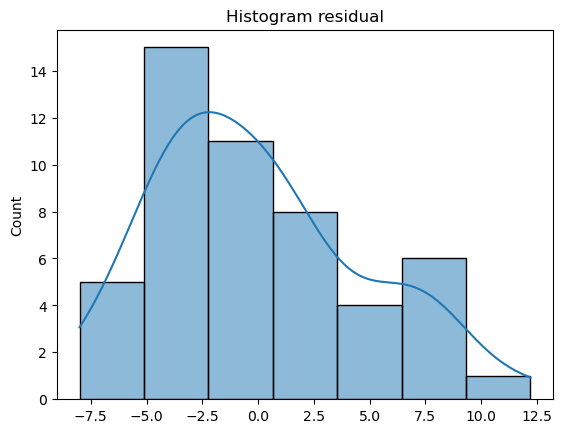

In [4]:
from statsmodels.stats.stattools import jarque_bera
import matplotlib.pyplot as plt
import seaborn as sns

nrumah = pd.read_csv("data/latihan_normalitas_3.csv")
sampel_model_n = nrumah[
    ["Harga", "Luas_Bangunan", "Jumlah_Kamar", "Usia_Rumah"]
].dropna()
X_model_n = sampel_model_n[["Luas_Bangunan", "Jumlah_Kamar", "Usia_Rumah"]]
y_model_n = sampel_model_n["Harga"]

model_n = LinearRegression()
model_n.fit(X_model_n, y_model_n)

prediksi_model_n = pd.Series(model_n.predict(X_model_n), index=y_model_n.index)
residu_model_n = y_model_n - prediksi_model_n

jb, p_jb, skew, kurt = jarque_bera(residu_model_n)
print(f"Jarque-Bera = {jb:.4f}, p = {p_jb:.4f}")

sns.histplot(residu_model_n, kde=True)
plt.title("Histogram residual")
plt.show()



Kesimpulan: p = 0,2032 di atas 0,05, jadi residual tidak menyimpang
jauh dari normal menurut uji ini; gagal menolak bukan membuktikan normalitas.



## Latihan 3: kasus tanpa pelanggaran (hetero-1)



In [5]:
jual = pd.read_csv("data/hetero_1.csv")
sampel_model_jual = jual[["Penjualan", "Iklan", "Salesperson", "Diskon"]].dropna()
X_model_jual = sampel_model_jual[["Iklan", "Salesperson", "Diskon"]]
y_model_jual = sampel_model_jual["Penjualan"]

model_jual = LinearRegression()
model_jual.fit(X_model_jual, y_model_jual)

prediksi_model_jual = pd.Series(
    model_jual.predict(X_model_jual), index=y_model_jual.index
)
residu_model_jual = y_model_jual - prediksi_model_jual
Xj = sm.add_constant(jual[["Iklan", "Salesperson", "Diskon"]])
print("BP p   :", round(het_breuschpagan(residu_model_jual, Xj)[1], 4))
print("White p:", round(het_white(residu_model_jual, Xj)[1], 4))



BP p   : 0.9969
White p: 0.5424


Kesimpulan: kedua uji tidak menolak homoskedastis (p = 0,997 dan 0,542).
Dugaan "variabilitas penjualan membesar saat iklan tinggi" tidak
didukung data ini. Yang benar: laporkan apa adanya, jangan paksakan
narasi. Ini juga contoh bahwa hipotesis bisa ditolak data.
